In [68]:
import matplotlib.pyplot as plt
import networkx as nx
import h5py
import numpy as np
import pandas as pd
import re
import os
import sys

import mouse1d_analysis as m1da

sys.path.append("/../../HALnalysis")
import analysis_package as mla

from mouse1d_analysis import Burst

import regex as re

In [69]:
#Get bursts from raw data
homedir=os.path.expanduser("~")

filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/7-9 mouse_1d_test/7/well4/"
filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/2h_7-12/M07484/240712/4/well4/"

filename = "2h_7-12_well_4"
#filename = "2h_well_4"
filetag = ".raw.h5"
datapath = homedir + "/Documents/HAL/data/wes_analysis/"
well_no = 4
recording_no = 0

In [70]:
events = mla.load_events(filepath + filename + filetag, well_no)
display(events)

,frameno,eventtype,eventid,eventmessage,frameno_adjusted,time,eventmessage_decoded
0,25044376,1,1,"b'{""before_training"":""1""}\n'",50508,5.0508,"{""before_training"":""1""}\n"
1,25044427,1,7,"b'{""map"":""1000"",""moveto"":""3"",""object"":""0""}\n'",50559,5.0559,"{""map"":""1000"",""moveto"":""3"",""object"":""0""}\n"
2,25683540,1,6,"b'{""map"":""1000"",""moveto"":""2"",""object"":""0""}\n'",689672,68.9672,"{""map"":""1000"",""moveto"":""2"",""object"":""0""}\n"
3,26068653,1,5,"b'{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n'",1074785,107.4785,"{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n"
4,26136153,1,4,"b'{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n'",1142285,114.2285,"{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n"
...,...,...,...,...,...,...,...
12742,97023988,1,134,"b'{""amp_mV"":""40.0"",""dac"":""1"",""num_trains"":""1"",...",72030120,7203.0120,"{""amp_mV"":""40.0"",""dac"":""1"",""num_trains"":""1"",""p..."
12743,97034515,1,133,"b'{""end_stimulation"":""l3""}\n'",72040647,7204.0647,"{""end_stimulation"":""l3""}\n"
12744,97034516,1,137,"b'{""end_stimulation"":""loc3_distance""}\n'",72040648,7204.0648,"{""end_stimulation"":""loc3_distance""}\n"
12745,97034570,1,136,"b'{""start_stimulation"":""loc3_distance""}\n'",72040702,7204.0702,"{""start_stimulation"":""loc3_distance""}\n"


In [71]:
pre_train_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
train_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
full_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])


current_pos = -1
world = None

for i in events.index:
    
    message = events.loc[i, "eventmessage_decoded"]
    if "moveto" in message:
        numbers = [int(num) for num in re.findall(r'\d+', message)]
        if not world:
            world = list(str(numbers[0]))
        new_pos = numbers[1]
        
        if new_pos != current_pos:
            movement_df.loc[len(movement_df), :] = [events.loc[i, "frameno_adjusted"], events.loc[i, "time"], new_pos]
            full_movement_df.loc[len(full_movement_df), :] = [events.loc[i, "frameno_adjusted"], events.loc[i, "time"], new_pos]
            current_pos = new_pos
    elif message == "{\"training\":\"1\"}\n":
        print("switch to train")
        pre_train_movement_df = movement_df
        movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])


train_movement_df = movement_df
full_movement_df



switch to train


,frameno,time,position
0,50559,5.0559,3
1,689672,68.9672,2
2,1074785,107.4785,1
3,1142285,114.2285,0
4,1482407,148.2407,1
...,...,...,...
158,70233727,7023.3727,3
159,70605430,7060.543,2
160,70732884,7073.2884,1
161,70987764,7098.7764,0


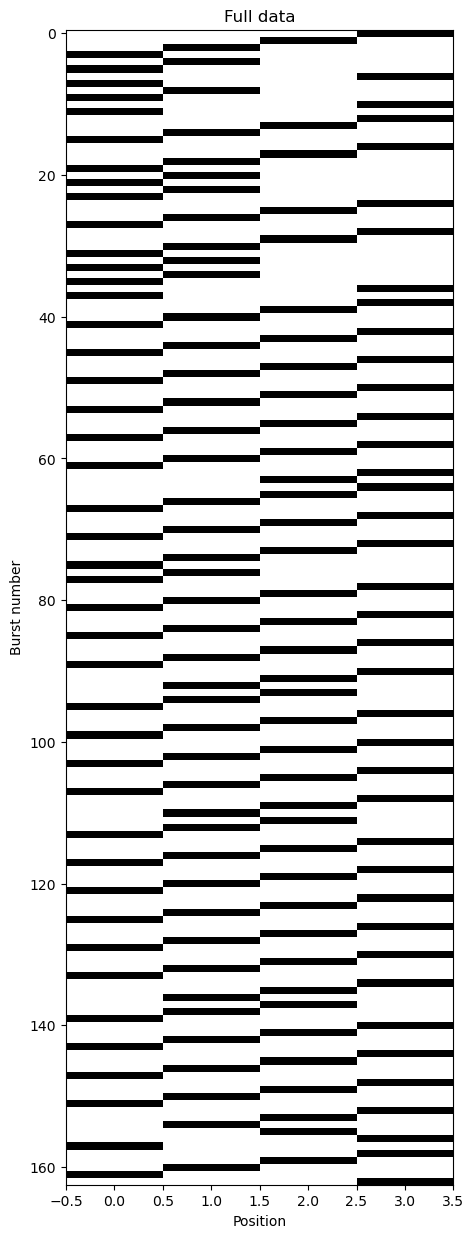

In [72]:
xtplot = np.zeros((len(full_movement_df), 1 + max(full_movement_df["position"])))
for i in full_movement_df.index:
    xtplot[i, full_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 15))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Full data")
plt.ylabel("Burst number")
plt.xlabel("Position")
plt.show()
#plt.close()

xtplot = np.zeros((len(pre_train_movement_df), 1 + max(pre_train_movement_df["position"])))
for i in pre_train_movement_df.index:
    xtplot[i, pre_train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("No stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


xtplot = np.zeros((len(train_movement_df), 1 + max(train_movement_df["position"])))
for i in train_movement_df.index:
    xtplot[i, train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


In [73]:

midway = (min(train_movement_df["frameno"]) + max(train_movement_df["frameno"]))/2

first_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] < midway, :].reset_index()
second_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] > midway, :].reset_index()

midway = (min(pre_train_movement_df["frameno"]) + max(pre_train_movement_df["frameno"]))/2

first_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] < midway, :].reset_index()
second_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] > midway, :].reset_index()

In [74]:
train_transition_df = m1da.build_transition_df(train_movement_df, world)
pre_train_transition_df = m1da.build_transition_df(pre_train_movement_df, world)
first_half_train_transition_df = m1da.build_transition_df(first_half_train_movement_df, world)
second_half_train_transition_df = m1da.build_transition_df(second_half_train_movement_df, world)

first_half_pre_train_transition_df = m1da.build_transition_df(first_half_pre_train_movement_df, world)
second_half_pre_train_transition_df = m1da.build_transition_df(second_half_pre_train_movement_df, world)

train_transition_df

,leftward,rightward,total,proportion left,object
0,20.0,0.0,20.0,1.000000,1
1,19.0,4.0,23.0,0.826087,0
2,22.0,1.0,23.0,0.956522,0
3,19.0,1.0,20.0,0.950000,0


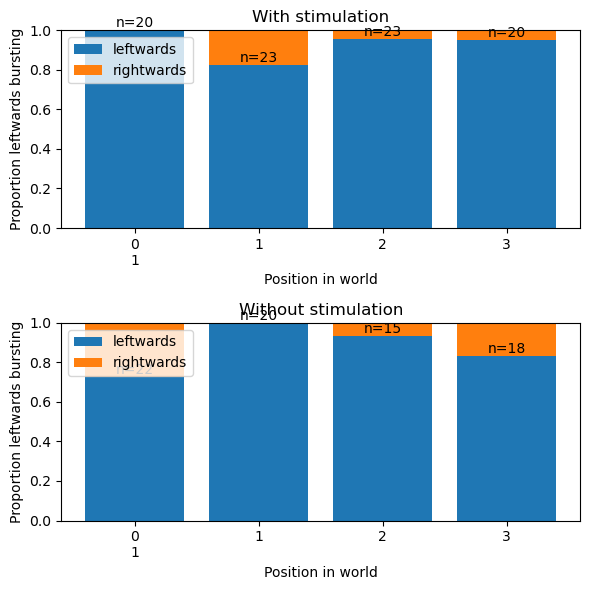

In [75]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
m1da.make_probability_bars(train_transition_df, world)

ax = plt.subplot(212)
plt.title("Without stimulation")
m1da.make_probability_bars(pre_train_transition_df, world)

plt.tight_layout()

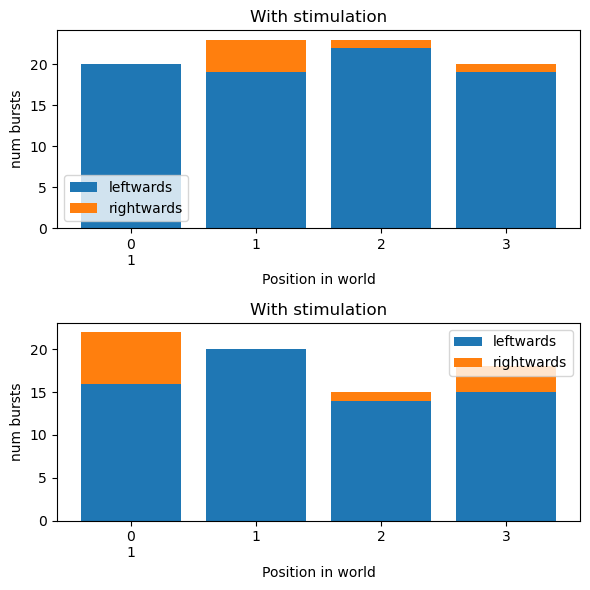

In [76]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
m1da.make_count_bars(train_transition_df, world)

ax = plt.subplot(212)
plt.title("Without stimulation")
m1da.make_count_bars(pre_train_transition_df, world)

plt.tight_layout()

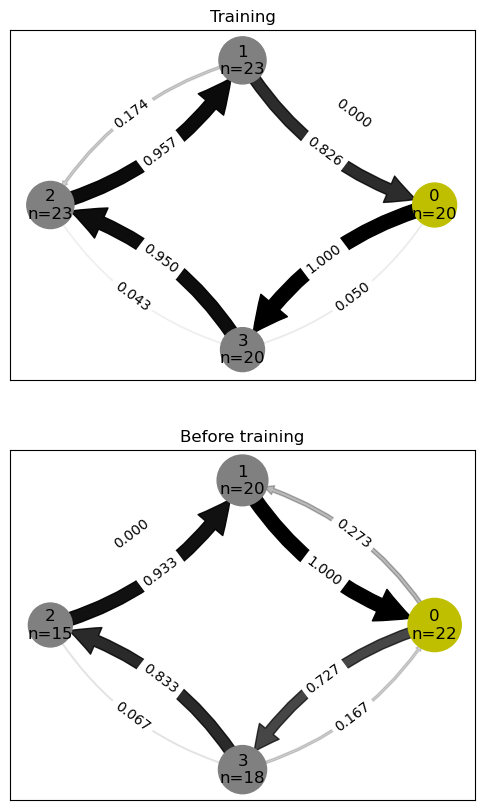

In [77]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("Training")
m1da.make_network_graph(train_transition_df, world)
plt.subplot(212)
plt.title("Before training")
m1da.make_network_graph(pre_train_transition_df, world)

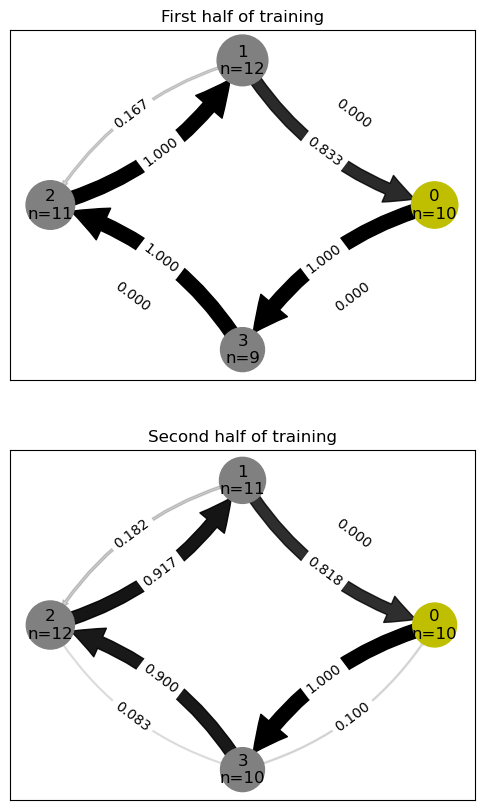

In [78]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_train_transition_df, world)

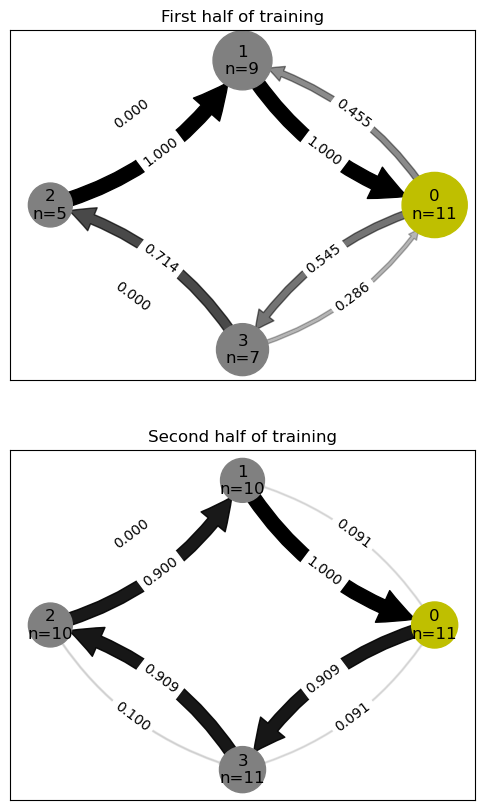

In [79]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_pre_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_pre_train_transition_df, world)

# Process the real data and get burst direction probabilities

In [80]:
display( train_movement_df)
display(pre_train_movement_df)
display(full_movement_df)

,frameno,time,position
0,36262993,3626.2993,1
1,36443515,3644.3515,0
2,37071670,3707.167,3
3,37315930,3731.593,2
4,37475262,3747.5262,1
...,...,...,...
82,70233727,7023.3727,3
83,70605430,7060.543,2
84,70732884,7073.2884,1
85,70987764,7098.7764,0


,frameno,time,position
0,50559,5.0559,3
1,689672,68.9672,2
2,1074785,107.4785,1
3,1142285,114.2285,0
4,1482407,148.2407,1
...,...,...,...
71,33693451,3369.3451,0
72,34835130,3483.513,3
73,35112518,3511.2518,2
74,35461070,3546.107,1


,frameno,time,position
0,50559,5.0559,3
1,689672,68.9672,2
2,1074785,107.4785,1
3,1142285,114.2285,0
4,1482407,148.2407,1
...,...,...,...
158,70233727,7023.3727,3
159,70605430,7060.543,2
160,70732884,7073.2884,1
161,70987764,7098.7764,0


['events', 'groups', 'recording_id', 'settings', 'spikes', 'start_time', 'stop_time', 'well_id']
              time  channel  amplitude
0          -0.1829      299  -4.543872
1           0.4245     1021  -8.561347
2           0.4256      465   6.110578
3           0.4487      299  -5.539350
4           0.4509      559  -5.208086
...            ...      ...        ...
2195820  7204.9520      952  -4.684583
2195821  7204.9546      934  -4.392340
2195822  7204.9604      262  -5.841686
2195823  7205.0066      299  -4.883385
2195824  7205.0090      599  -6.283824

[2195825 rows x 3 columns]


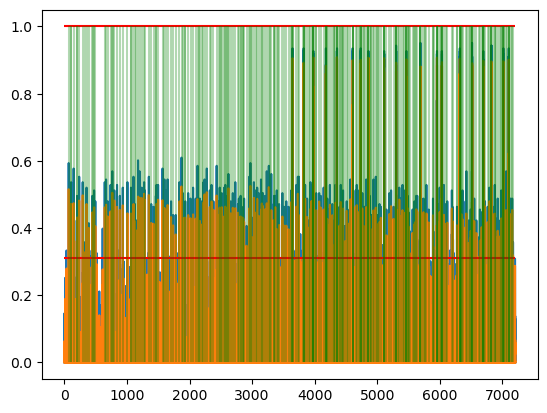

burst found in bin 6840 (time 68.40 s)
burst found in bin 10696 (time 106.96 s)
burst found in bin 11356 (time 113.56 s)
burst found in bin 14770 (time 147.70 s)
burst found in bin 19753 (time 197.53 s)
burst found in bin 20302 (time 203.02 s)
burst found in bin 23658 (time 236.58 s)
burst found in bin 29251 (time 292.51 s)
burst found in bin 32452 (time 324.52 s)
burst found in bin 35393 (time 353.93 s)
burst found in bin 38939 (time 389.39 s)
burst found in bin 44685 (time 446.85 s)
burst found in bin 46048 (time 460.48 s)
burst found in bin 47466 (time 474.66 s)
burst found in bin 49440 (time 494.40 s)
burst found in bin 64431 (time 644.31 s)
burst found in bin 66594 (time 665.94 s)
burst found in bin 69272 (time 692.72 s)
burst found in bin 73759 (time 737.59 s)
burst found in bin 76517 (time 765.17 s)
burst found in bin 77987 (time 779.87 s)
burst found in bin 79785 (time 797.85 s)
burst found in bin 84102 (time 841.02 s)
burst found in bin 88591 (time 885.91 s)
burst found in bin

In [90]:
burst_list = m1da.find_bursts(filepath, filename, well_no, recording_no, burst_thresh = 8, datapath = datapath, stim_thresh = 1) # don't filter out stimulations by burst size - do it with events.
print(len(burst_list))

In [91]:
p = re.compile(r"stimulation\":\"\L<world_locs>\"", world_locs=set(world))

#this intermediate step isn't actually necessary
stimulation_events = events.loc[["stimulation" in i for i in events["eventmessage_decoded"]], :]
# for i in stimulation_events["eventmessage_decoded"]:
#     print(i)


big_stimulation_events = stimulation_events.loc[[not (p.search(i) is None) for i in stimulation_events["eventmessage_decoded"]], :]
big_stimulation_events.head()

,frameno,eventtype,eventid,eventmessage,frameno_adjusted,time,eventmessage_decoded
208,61437433,1,138,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""3"",""...",36443565,3644.3565,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""3"",""ph..."
209,61470780,1,139,"b'{""end_stimulation"":""1""}\n'",36476912,3647.6912,"{""end_stimulation"":""1""}\n"
814,63212492,1,138,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""3"",""...",38218624,3821.8624,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""3"",""ph..."
815,63245839,1,139,"b'{""end_stimulation"":""1""}\n'",38251971,3825.1971,"{""end_stimulation"":""1""}\n"
1367,64753950,1,138,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""3"",""...",39760082,3976.0082,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""3"",""ph..."


In [92]:
trimmed_burst_list = list()
for i, burst in enumerate(burst_list):
    time = burst.time
    sub_big_stimulation_events = big_stimulation_events.loc[big_stimulation_events["time"] < time + 0.5].reset_index(drop = True)
    if len(sub_big_stimulation_events) > 0 and "start_stimulation" in sub_big_stimulation_events.loc[len(sub_big_stimulation_events) - 1, "eventmessage_decoded"]:
        #print(sub_big_stimulation_events.loc[len(sub_big_stimulation_events) - 1, :])
        print("removing burst at time " + str(time))
    else:
        trimmed_burst_list.append(burst)

removing burst at time 3644.0300000000034
removing burst at time 3645.160000000003
removing burst at time 3646.240000000003
removing burst at time 3821.5100000000034
removing burst at time 3822.6700000000033
removing burst at time 3823.770000000003
removing burst at time 3975.6900000000037
removing burst at time 3976.7900000000036
removing burst at time 3977.8700000000035
removing burst at time 4177.5800000000045
removing burst at time 4178.710000000004
removing burst at time 4179.800000000004
removing burst at time 4354.0800000000045
removing burst at time 4355.160000000004
removing burst at time 4356.260000000004
removing burst at time 4604.870000000004
removing burst at time 4605.960000000005
removing burst at time 4607.090000000005
removing burst at time 4732.400000000004
removing burst at time 4733.510000000005
removing burst at time 4734.670000000005
removing burst at time 4855.800000000005
removing burst at time 4856.880000000005
removing burst at time 4857.990000000004
removing

[68.21000000000006, 106.7700000000001, 113.3700000000001, 147.51000000000013, 197.34000000000017, 202.83000000000018, 236.3900000000002, 292.3200000000003, 324.33000000000027, 353.7400000000003, 389.20000000000033, 446.6600000000004, 460.2900000000004, 474.4700000000004, 494.21000000000043, 644.1200000000006, 665.7500000000006, 692.5300000000005, 737.4000000000005, 764.9800000000006, 779.6800000000006, 797.6600000000007, 840.8300000000007, 885.7200000000007, 932.7500000000008, 1007.0700000000008, 1064.3200000000008, 1072.0700000000008, 1103.870000000001, 1126.700000000001, 1149.440000000001, 1176.630000000001, 1201.010000000001, 1235.7600000000011, 1273.400000000001, 1286.310000000001, 1349.1400000000012, 1387.3500000000013, 1423.9800000000012, 1461.6300000000012, 1471.4300000000012, 1497.0300000000013, 1567.9300000000014, 1598.1300000000015, 1623.6000000000015, 1649.1300000000015, 1704.1300000000015, 1737.1200000000015, 1779.1100000000015, 1838.3000000000015, 1871.1100000000017, 1892.

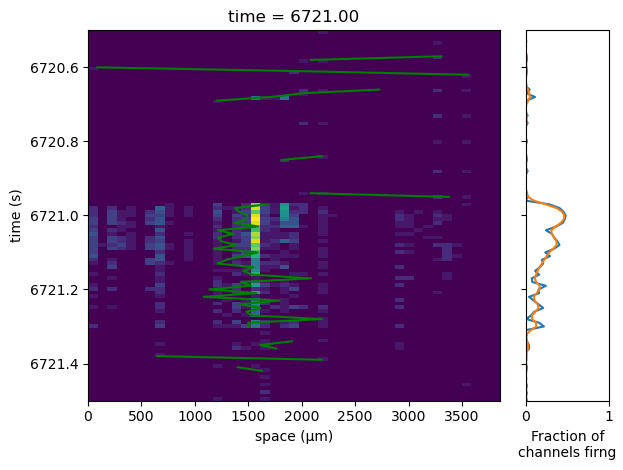

-187.84745762711873


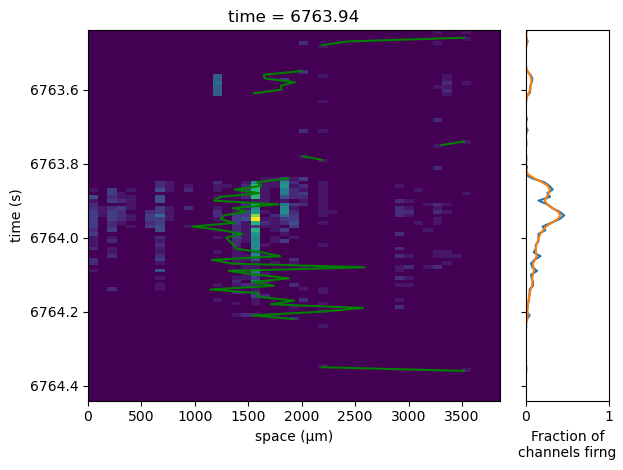

-605.2543859649122


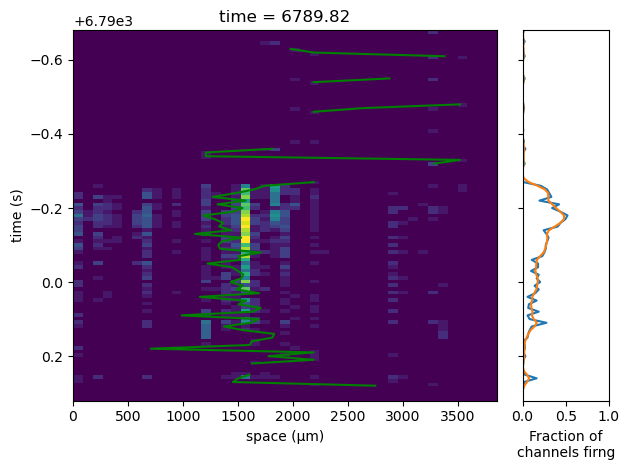

-552.8064903846155


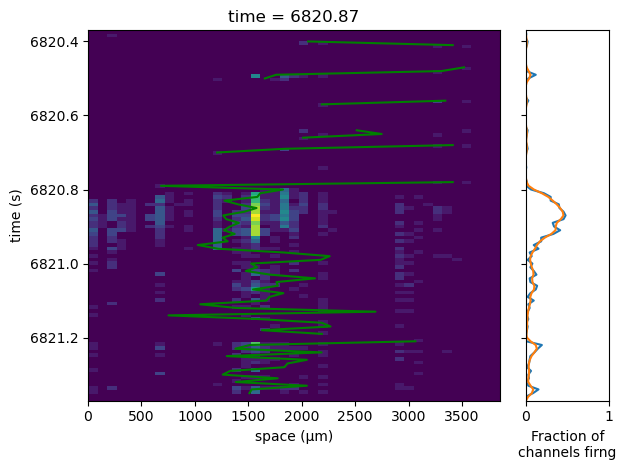

-347.49529190207136


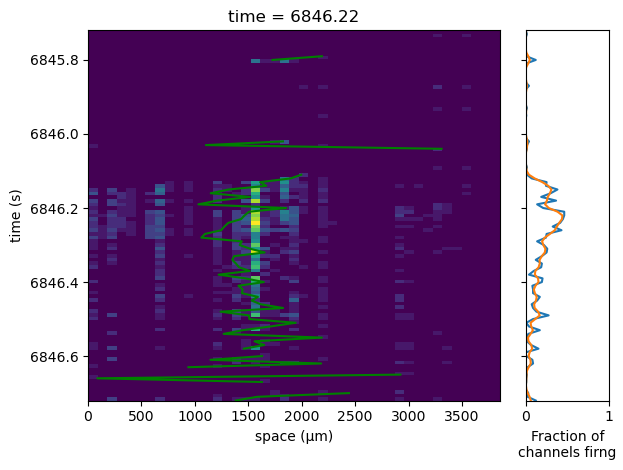

-431.0526315789473


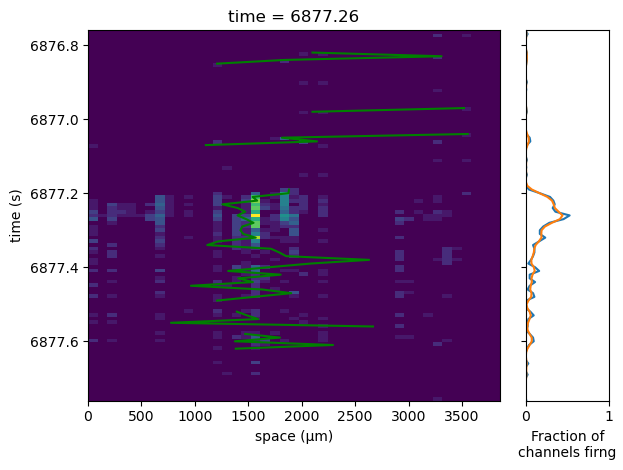

-476.64102564102564


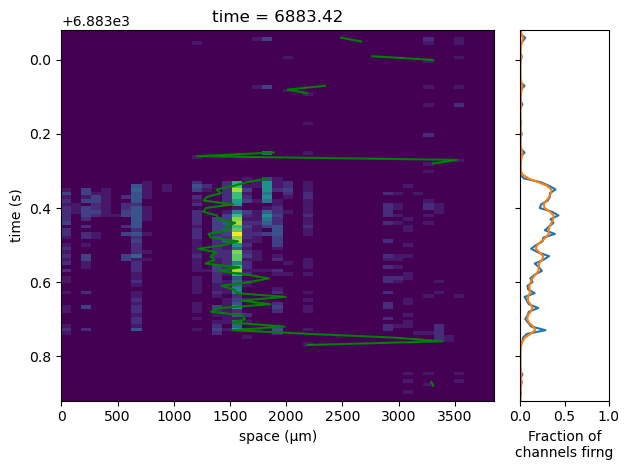

-271.1792452830189


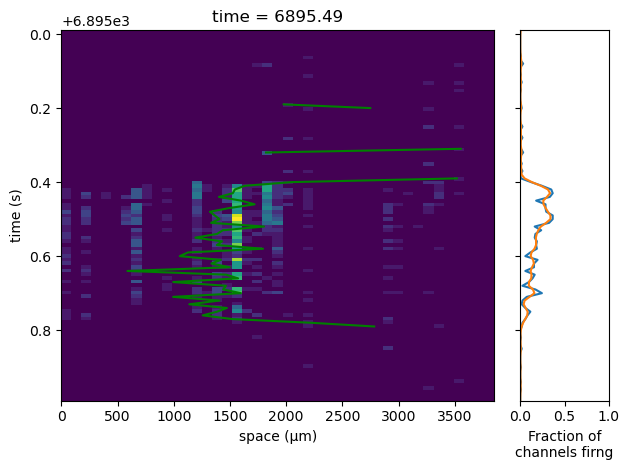

-683.6666666666667


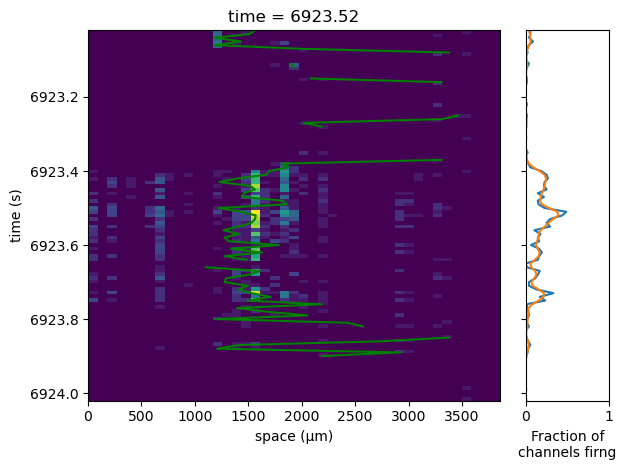

-126.8115942028985


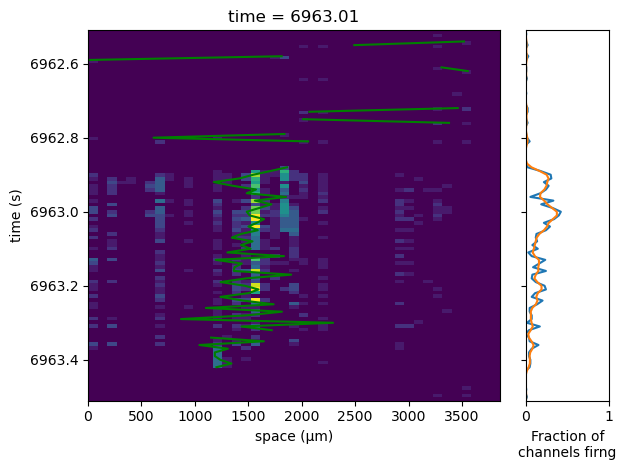

-194.5454545454545


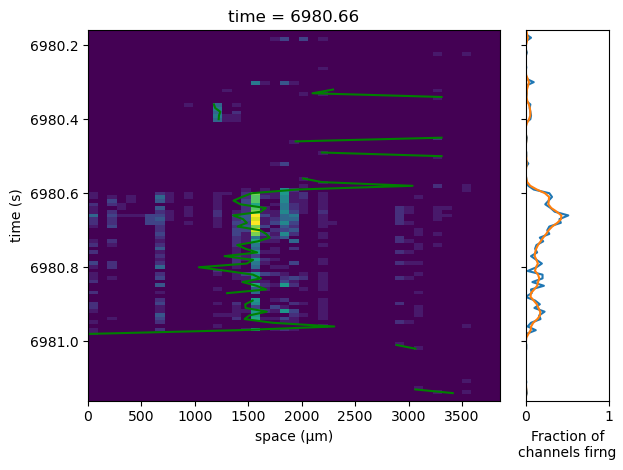

-599.5833333333333


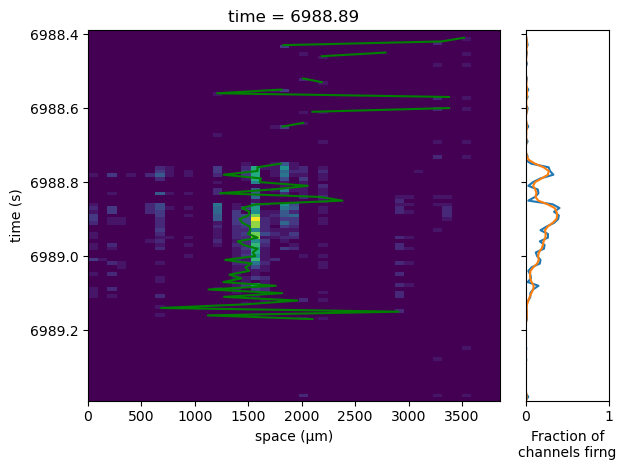

-219.04761904761904


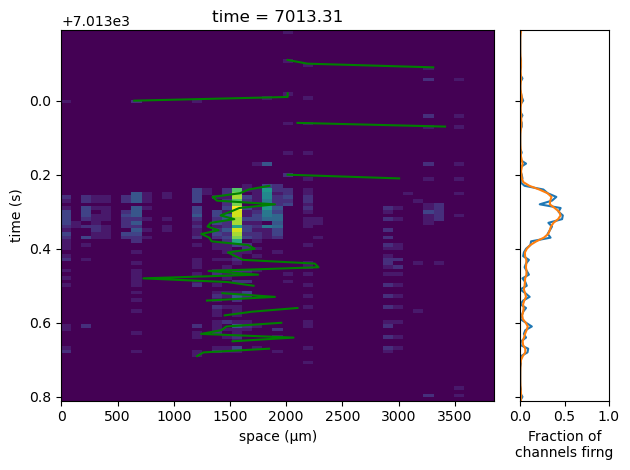

-432.8531073446329


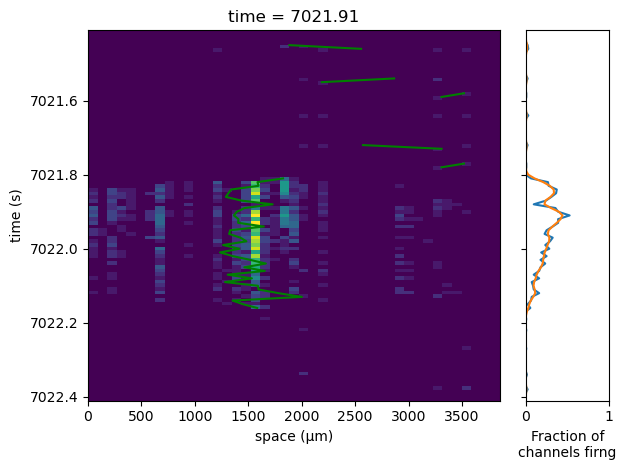

-459.6442307692307


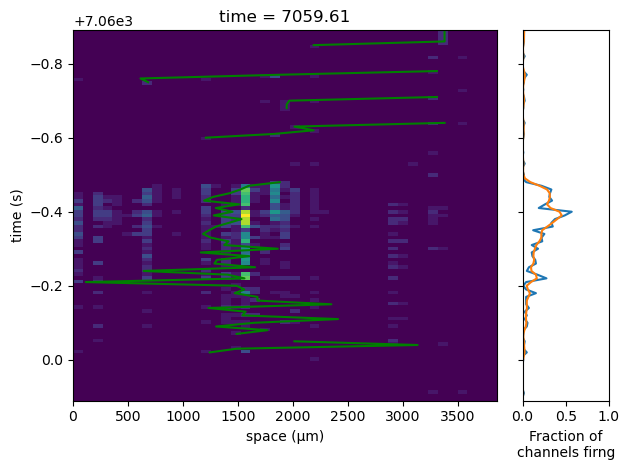

-317.85185185185196


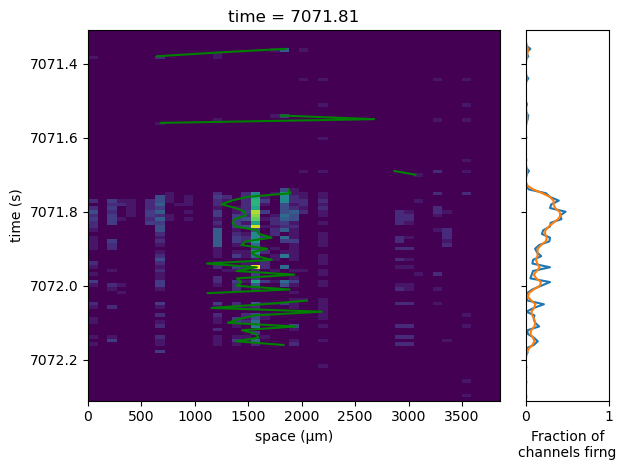

-419.0392156862745


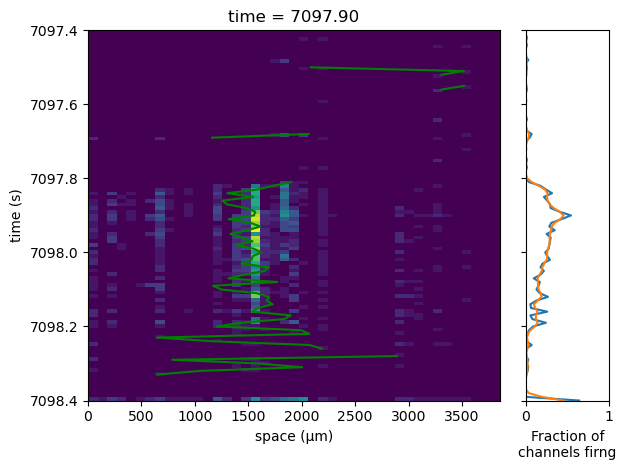

-178.11058344640446


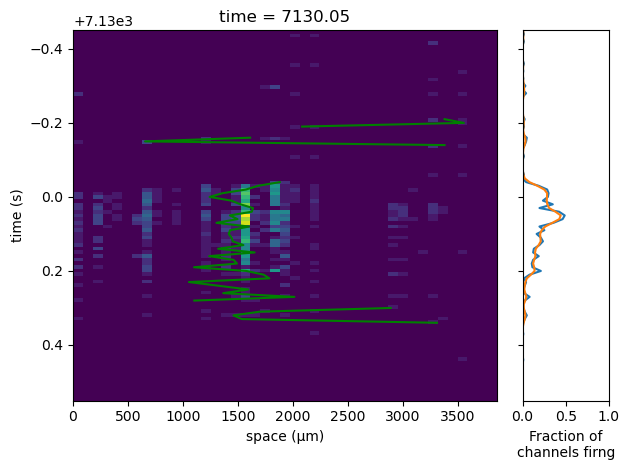

-256.03260869565224


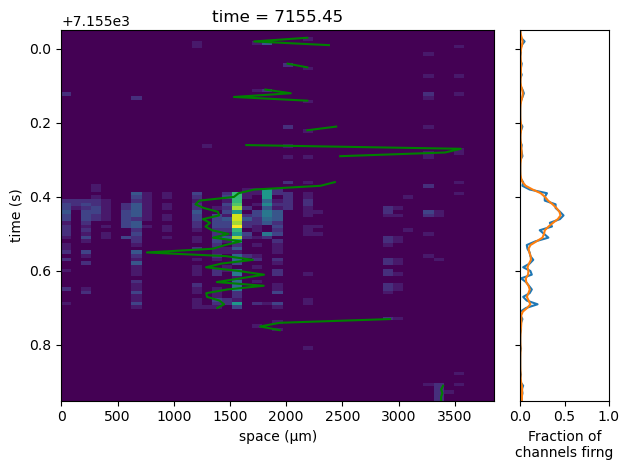

-312.8461538461538


In [99]:
print([i.time for i in trimmed_burst_list])
for i in list(trimmed_burst_list)[-20:-1]:
    i.plot()
    print(i.burst_direction(0.1))

In [100]:
def get_position_when_burst(burst: Burst, movement_df: pd.DataFrame)-> int:
    time = burst.time

    position = -1
    

    for i in movement_df.index:
        previous_position = position

        transition_time = movement_df.loc[i, "time"]
        position = movement_df.loc[i, "position"]

        if time < transition_time:
            return previous_position
    

    return position
    

3
2
1
0
1
1
1
0
3
3
3
0
1
0
3
3
0
0
0
3
2
1
0
3
3
2
1
0
1
0
0
0
0
1
0
3
3
3
3
2
2
1
0
3
2
2
1
0
0
1
0
1
1
0
0
3
0
3
3
3
3
2
2
1
0
0
3
2
1
0
3
3
3
3
2
2
1
0
0
3
3
2
2
1
0
3
3
2
1
0
0
3
2
2
2
1
0
3
3
2
3
3
2
1
0
0
3
2
1
0
0
0
0
3
2
1
0
1
0
3
2
1
0
3
3
3
2
1
0
0
0
3
2
2
1
0
3
2
1
2
2
2
1
0
0
0
0
0
3
3
3
3
2
1
0
3
2
1
0
3
3
2
1
0
0
0
0
3
3
2
2
1
2
1
0
0
3
2
1
0
3
3
3
2
1
0
3
3
3
3
3
3
2
2
1
0
0
3
2
2
2
1
1
1
0
3
2
1
0
3
2
2
1
2
1
1
0
0
3
3
2
1
1
1
1
1
0
3
2
2
2
1
0
3
2
2
1
0
3
3
2
1
1
1
2
3
0
3
2
1
0
0
3


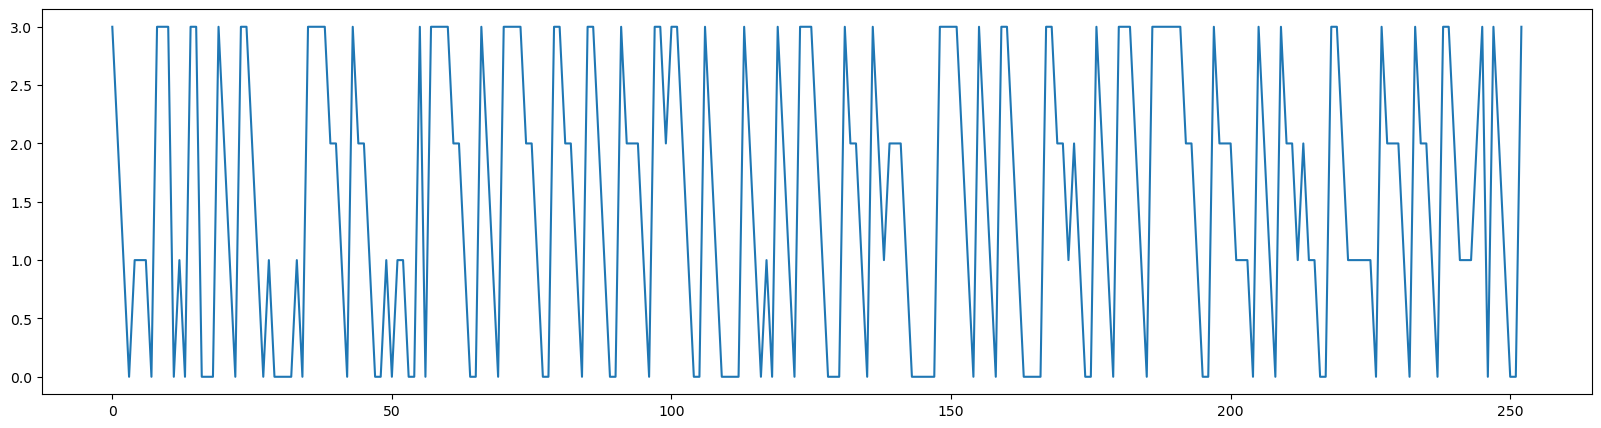

In [101]:
for burst in trimmed_burst_list:
    print(get_position_when_burst(burst, full_movement_df))

plt.figure(figsize = (20, 5))
plt.plot([get_position_when_burst(i, full_movement_df) for i in trimmed_burst_list])

In [105]:
raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
raw_data_transition_df["leftward"] = 0
raw_data_transition_df["rightward"] = 0


raw_data_transition_df["object"] = list(world)
display(raw_data_transition_df)
for burst in trimmed_burst_list:
    burst_direction = burst.burst_direction()
    position = get_position_when_burst(burst, full_movement_df)
    if burst_direction < 0:
        raw_data_transition_df.loc[position, "leftward"] += 1
    else:
        raw_data_transition_df.loc[position, "rightward"] += 1
    
raw_data_transition_df["total"] = raw_data_transition_df["leftward"] + raw_data_transition_df["rightward"] 
raw_data_transition_df["proportion left"] = raw_data_transition_df["leftward"]/raw_data_transition_df["total"]

raw_data_transition_df



,leftward,rightward,total,proportion left,object
0,0,0,NaN,NaN,1
1,0,0,NaN,NaN,0
2,0,0,NaN,NaN,0
3,0,0,NaN,NaN,0


,leftward,rightward,total,proportion left,object
0,60,10,70,0.857143,1
1,51,4,55,0.927273,0
2,49,7,56,0.875000,0
3,62,10,72,0.861111,0


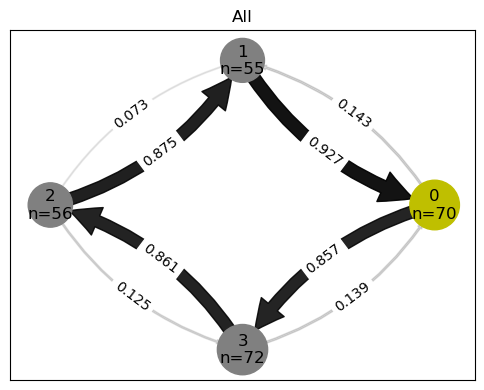

In [106]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("All")
m1da.make_network_graph(raw_data_transition_df, world)